# Project 5 – Laptop Lifecycle: 2026 Refresh Programme Analysis

**Source:** `data/raw/laptop_lifecycle.csv`, the tracker an IT team used to replace every employee's laptop in 2026 (June–October).
Each row is one employee. The columns follow the replacement process from left to right:

| Step | Column(s) | What it records |
|---|---|---|
| 1 | Email sent | The user was told about the swap |
| 2 | Laptop Received | The new laptop arrived from the vendor |
| 3 | Keyed Date | The new laptop was set up (imaged and keyed to the user) |
| 4 | Shipping Date, Tracking | The new laptop was shipped, with a courier tracking number |
| 5 | New Serial / Asset Tag / Host | The new device's identity |
| 6 | Added to Teams, Asset Panda, Group Memberships | Accounts and asset records updated |
| 7 | Old Laptop Return Tracking | A return label for the old laptop |
| 8 | Old Laptop Received and Panda updated, INTUNE updated | The old laptop came back and was closed off |
| 9 | Removal from Team Viewer | The old laptop was removed from remote support |

**Note on privacy:** names, emails, employee IDs, serial numbers, asset tags and tracking numbers in this public copy are replaced with consistent fake values.
Locations, dates and statuses are real, so the analysis is unchanged.

### Business questions
1. **BQ1 Programme progress:** how many users have their new laptop?
2. **BQ2 Process completion:** which steps get done, and which get skipped?
3. **BQ3 Turnaround:** how long from set-up to shipping?
4. **BQ4 Shipping waves:** when did the volume peak?
5. **BQ5 Old-laptop recovery:** how many old laptops came back?
6. **BQ6 Location:** do home-based (WFH) users differ from office users?

In [1]:
# Import the libraries we need
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# One simple chart style for the whole notebook
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 13,
    "font.size": 10, "legend.frameon": False,
})
# Colours with one job each, used the same way in every chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # categories, in this order
GREEN, RED, GREY = "#0ca30c", "#d03b3b", "#b5b4ae"       # good / problem / not applicable
os.makedirs("../images", exist_ok=True)                   # charts are saved here for the README

## 1. Load and understand the data

In [2]:
# The file was saved from Excel on Windows, so it uses the cp1252 encoding (utf-8 would fail on some characters)
raw = pd.read_csv("../data/raw/laptop_lifecycle.csv", encoding="cp1252", dtype=str)
print(raw.shape)
raw.head(3)

(523, 26)


,User ID (User Name),Update,User Name,E-Mail (User Name),Comp/Host Name,Asset Tag,Serial Number,Location,Email sent,Laptop Received,Keyed Date,Shipping Date,New Serial,New Asset Tag,New Host,Added to Teams,Asset Panda,Group Memberships,Tracking,Old Laptop Return Tracking,"Old Laptop Received and Panda updated, INTUNE updated",Reorder,Removal from Team Viewer,Teams,Reminder,Notes
0,EMP0001,NaN,User 0001,USER0001@EXAMPLE.COM,BMT-LTPF21F1A7,700001,PF21F1A7,"Brampton, ON",yes,Received,June 17,19-Jun-26,SDE8D6C1,700002,BMT-LTSDE8D6C1,Yes,Updated,Yes,925777064920,NaN,NaN,1,July 29th,NaN,NaN,NaN
1,EMP0002,NaN,User 0002,USER0002@EXAMPLE.COM,BMT-LT700003,700003,PF1431E3,"Brampton, ON",yes,Received,June 17,19-Jun-26,SD9BBC12,700004,BMT-LTSD9BBC12,Yes,Updated,Yes,981747944725,NaN,NaN,2,8/19/2026,NaN,NaN,NaN
2,EMP0003,NaN,User 0003,USER0003@EXAMPLE.COM,BMT-LT700005,700005,PF58146D,"Brampton, ON",yes,Received,June 17,19-Jun-26,SDD7D6BA,700006,BMT-LTSDD7D6BA,Yes,Updated,Yes,972868017768,NaN,NaN,3,July 29th,NaN,NaN,NaN


In [3]:
# Column names carry stray spaces ("New Serial ", "Reminder "). Strip them so they are easy to type.
raw.columns = raw.columns.str.strip()
raw.columns.tolist()

['User ID (User Name)',
 'Update',
 'User Name',
 'E-Mail (User Name)',
 'Comp/Host Name',
 'Asset Tag',
 'Serial Number',
 'Location',
 'Email sent',
 'Laptop Received',
 'Keyed Date',
 'Shipping Date',
 'New Serial',
 'New Asset Tag',
 'New Host',
 'Added to Teams',
 'Asset Panda',
 'Group Memberships',
 'Tracking',
 'Old Laptop Return Tracking',
 'Old Laptop Received and Panda updated, INTUNE updated',
 'Reorder',
 'Removal from Team Viewer',
 'Teams',
 'Reminder',
 'Notes']

## 2. Validate the data

In [4]:
# Check 1: completely blank rows (a lone "1" in the Reminder column does not make a real row)
blank = raw.drop(columns=["Reminder"]).isna().all(axis=1)
print("Blank rows:", blank.sum())

# Check 2: users listed more than once
ids = raw.loc[~blank, "User ID (User Name)"]
print("Users listed twice:", ids[ids.duplicated()].tolist())
raw[raw["User ID (User Name)"].isin(ids[ids.duplicated()])][["User ID (User Name)", "Location", "Keyed Date", "Shipping Date", "New Asset Tag", "Tracking"]]

Blank rows: 3
Users listed twice: ['EMP0488', 'EMP0272']


,User ID (User Name),Location,Keyed Date,Shipping Date,New Asset Tag,Tracking
271,EMP0272,"Weston, ON",29-Jul,5-Aug,700544,909431572387
487,EMP0488,"Brampton, ON",15-Sep,18-Sep,700976,914565006754
510,EMP0488,Ontario (WFH),NaN,NaN,NaN,NaN
518,EMP0272,"Weston, ON",NaN,NaN,700990,900811923940


In [5]:
# Check 3: yes/no columns typed in many ways
for col in ["Email sent", "Added to Teams", "Asset Panda", "Group Memberships", "Old Laptop Received and Panda updated, INTUNE updated"]:
    print(col, "->", raw[col].value_counts(dropna=False).to_dict())

Email sent -> {'Yes': 284, 'yes': 128, 'No': 72, 'no': 23, nan: 14, 'Check': 1, 'Out': 1}
Added to Teams -> {'Yes': 409, 'yes': 88, nan: 18, 'No': 6, 'no': 2}
Asset Panda -> {'Updated': 504, nan: 18, 'Upated': 1}
Group Memberships -> {'Yes': 469, 'yes': 25, nan: 18, 'No': 6, 'hello': 2, 'Hello': 2, 'ANA': 1}
Old Laptop Received and Panda updated, INTUNE updated -> {nan: 321, 'Yes': 98, 'YES': 68, 'Updated': 28, 'updated': 5, '1': 1, 'yes': 1, '940162356395': 1}


In [6]:
# Check 4: dates are typed without a year and in several formats
for col in ["Keyed Date", "Shipping Date", "Removal from Team Viewer"]:
    print(col, "->", sorted(raw[col].dropna().unique(), key=str)[:12], "...")

Keyed Date -> ['1-Sep', '10-Aug', '10-Jul', '10-Sep', '11-Sep', '12-Aug', '13-Aug', '14-Jul', '15-Jul', '15-Sep', '16-Jul', '17-Jun'] ...
Shipping Date -> ['10-Jul-26', '10-Sep', '11-Sep', '12-Aug', '14-Aug', '15-Jul-26', '17-Jul-26', '18-Aug', '18-Sep', '19-Aug', '19-Jun-26', '2-Sep'] ...
Removal from Team Viewer -> ['14-Oct', '16-Sep', '21-Oct', '26-Aug', '3-Sep', '30-Sep', '7-Oct', '8/12/2026', '8/19/2026', '8/5/2026', '9-Sep', '9/24/2026'] ...


In [7]:
# Check 5: text where a tracking number should be, and one tracking number reused many times
tracking = raw["Tracking"].dropna()
print("Non-numeric tracking values:", tracking[~tracking.str.fullmatch(r"\d+")].value_counts().to_dict())
top = tracking.value_counts().head(1)
print("Most repeated tracking number:", top.index[0], "used", top.iloc[0], "times")
print(raw[raw["Tracking"] == top.index[0]]["Location"].value_counts().to_dict())

Non-numeric tracking values: {'King': 3, 'Person F': 2}
Most repeated tracking number: 985895382525 used 25 times
{'Calgary, AB': 10, 'Nanaimo, BC': 4, 'Sudbury, ON': 4, 'Victoria, BC': 3, 'Moncton, NB': 3, 'Lethbridge, AB': 1}


In [8]:
# Check 6: new host names that skip the "LT" part (e.g. KST-SD... instead of KST-LTSD...)
new_host = raw["New Host"].dropna().str.strip()
print("New hosts without 'LT':", (~new_host.str.contains("-LT")).sum())
print("New hosts / serials with stray spaces:", (raw["New Host"].dropna() != new_host).sum(), "/",
      (raw["New Serial"].dropna() != raw["New Serial"].dropna().str.strip()).sum())

# Check 7: an empty column
print("Values in the 'Teams' column:", raw["Teams"].notna().sum())

New hosts without 'LT': 28
New hosts / serials with stray spaces: 23 / 31
Values in the 'Teams' column: 0


### Validation summary
* **3 blank rows** at the bottom (one holds only a stray `1` in Reminder) are removed.
* **2 users are listed twice.** For one, the second row is an almost empty re-entry with a different location. For the other, it repeats the user with a different new asset tag and tracking number. The first record of each is kept.
* **Yes/no values are typed many ways:** `Yes`/`yes`/`YES`, `Updated`/`updated` and the typo `Upated`, plus stray values like `Check`, `Out`, `hello` and `ANA`. They are standardised to True/False; the stray values count as "not confirmed".
* **Dates have no year and come in five formats** (`29-Jul`, `19-Jun-26`, `June 17`, `8/19/2026`, `July 29th`). One keyed date is an Excel serial number (`46191`) and one is the word `No`. All are converted to 2026 dates, except `No`.
* **Tracking column problems:** 5 cells hold text instead of a tracking number (`King`, and a person's name). One tracking number is reused for **25 users in 6 different cities**, which can't be one shipment, so it is likely a copy-down error. In the old-laptop column, one cell holds a tracking number instead of Yes/No.
* **28 new host names skip the `LT` part** (e.g. `KST-SD…` instead of `KST-LTSD…`), and 23 new host names and 31 new serials have stray spaces. That will break exact matches in other systems, which is exactly what the Secure Boot project ran into.
* **The `Teams` column is completely empty.**

## 3. Clean the data

In [9]:
# 1) Drop the blank rows and keep the first record of each user
df = raw[~blank].drop_duplicates(subset="User ID (User Name)", keep="first").copy()
print("Users:", len(df))

# 2) Turn each step into a simple True/False flag.
#    Lower-case and trim each value, then check it against the words that mean "done".
yes_words = ["yes", "updated", "upated", "received", "1"]     # "upated" is a typo in the data
for col, flag in [("Email sent", "email_sent"), ("Laptop Received", "laptop_received"), ("Added to Teams", "added_to_teams"),
                  ("Asset Panda", "asset_panda_updated"), ("Group Memberships", "groups_done"),
                  ("Old Laptop Received and Panda updated, INTUNE updated", "old_laptop_closed")]:
    df[flag] = df[col].fillna("").str.strip().str.lower().isin(yes_words)   # "hello" / "ANA" do not count as yes

# Tracking columns count only when they hold a real 12-digit tracking number
df["shipment_tracked"] = df["Tracking"].fillna("").str.strip().str.fullmatch(r"\d{12}")
df["return_label"] = df["Old Laptop Return Tracking"].fillna("").str.strip().str.fullmatch(r"\d{12}")
df["teamviewer_removed"] = df["Removal from Team Viewer"].notna()

Users: 518


In [10]:
# 3) Dates: the team typed them in five different ways, mostly without a year (the year is 2026).
#    Try each format in turn; each attempt fills in the dates the earlier ones could not read.
for col, new in [("Keyed Date", "keyed"), ("Shipping Date", "shipped"), ("Removal from Team Viewer", "teamviewer_date")]:
    text = df[col].str.strip().str.replace(r"(st|nd|rd|th)$", "", regex=True)          # "July 29th" -> "July 29"
    serial = pd.to_numeric(text, errors="coerce")                                       # "46191" is an Excel date number
    df[new] = (pd.to_datetime(serial, unit="D", origin="1899-12-30")
               .fillna(pd.to_datetime(text + "-2026", format="%d-%b-%Y", errors="coerce"))   # "29-Jul"
               .fillna(pd.to_datetime(text, format="%d-%b-%y", errors="coerce"))            # "19-Jun-26"
               .fillna(pd.to_datetime(text + " 2026", format="%B %d %Y", errors="coerce"))  # "June 17"
               .fillna(pd.to_datetime(text, format="%m/%d/%Y", errors="coerce")))           # "8/19/2026"

print("Unreadable keyed dates:", df.loc[df["keyed"].isna() & df["Keyed Date"].notna(), "Keyed Date"].tolist())
print("Shipping dates read:", df["shipped"].notna().sum(), "| range:", df["shipped"].min().date(), "to", df["shipped"].max().date())

Unreadable keyed dates: ['No']
Shipping dates read: 503 | range: 2026-06-19 to 2026-10-20


In [11]:
# 4) Location: province and home-based (WFH) flag
province_names = {"Ontario": "ON", "Quebec": "QC", "Alberta": "AB", "British Columbia": "BC", "Nova Scotia": "NS",
                  "Manitoba": "MB", "New Brunswick": "NB", "Saskatchewan": "SK"}
df["wfh"] = df["Location"].str.contains("WFH")
df["province"] = df["Location"].str.extract(r",\s*([A-Z]{2})\s*$")[0]
for name, code in province_names.items():
    df.loc[df["Location"].str.startswith(name) & df["wfh"], "province"] = code
df.loc[df["Location"] == "Vancouver", "province"] = "BC"
print("Users without a province:", df["province"].isna().sum())
df["province"].value_counts()

Users without a province: 0


province
ON    299
AB     62
BC     60
QC     55
SK     13
MB     13
NS      7
NB      5
NL      3
PE      1
Name: count, dtype: int64

In [12]:
# 5) Save a tidy copy for reuse
clean = df[["User ID (User Name)", "Location", "province", "wfh", "email_sent", "laptop_received", "keyed", "shipped",
            "added_to_teams", "asset_panda_updated", "groups_done", "shipment_tracked", "return_label", "old_laptop_closed",
            "teamviewer_removed", "teamviewer_date"]].rename(columns={"User ID (User Name)": "user_id", "Location": "location"})
os.makedirs("../data/processed", exist_ok=True)
clean.to_csv("../data/processed/laptop_lifecycle_clean.csv", index=False)
print(clean.shape)

(518, 16)


## 4. Analysis

### BQ1 – Programme progress

In [13]:
users = len(df)
shipped = df["shipped"].notna()
print(f"Users in the programme: {users}")
print(f"New laptop shipped: {shipped.sum()} ({shipped.mean():.1%})")
not_started = df[~df["email_sent"] & df["keyed"].isna() & ~shipped]
print("Not started yet (no email, not keyed, not shipped):", len(not_started))
print("Started but not shipped:", (~shipped).sum() - len(not_started))

Users in the programme: 518
New laptop shipped: 503 (97.1%)
Not started yet (no email, not keyed, not shipped): 12
Started but not shipped: 3


**Finding:** **503 of 518 users (97.1%) have been shipped a new laptop**, between 19 Jun and 20 Oct 2026. 12 users haven't started at all (no email, not set up, not shipped) and 3 are part-way through.

**Recommendation:** Book the last 15 users into one final batch, and close the programme once they're shipped.

### BQ2 – Process completion

1. Email sent                    79.3
2. Laptop received               97.3
3. Keyed (set up)                97.1
4. Shipped                       97.1
4b. Shipment tracked             95.8
6a. Added to Teams               95.8
6b. Asset Panda updated          97.3
6c. Group memberships            95.2
7. Old-laptop return label       49.4
8. Old laptop back and closed    38.6
9. Removed from TeamViewer       82.6
dtype: float64


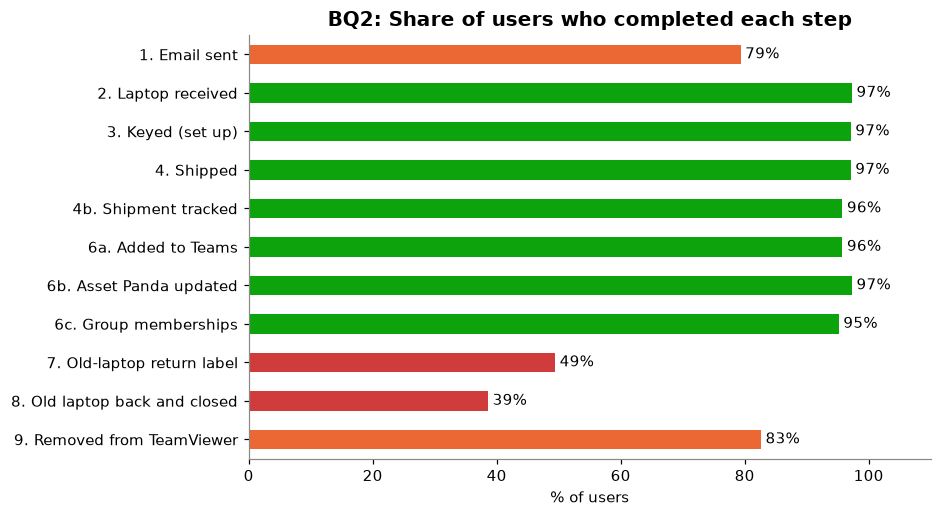

In [14]:
steps = pd.Series({
    "1. Email sent": df["email_sent"].mean(),
    "2. Laptop received": df["laptop_received"].mean(),
    "3. Keyed (set up)": df["keyed"].notna().mean(),
    "4. Shipped": shipped.mean(),
    "4b. Shipment tracked": df["shipment_tracked"].mean(),
    "6a. Added to Teams": df["added_to_teams"].mean(),
    "6b. Asset Panda updated": df["asset_panda_updated"].mean(),
    "6c. Group memberships": df["groups_done"].mean(),
    "7. Old-laptop return label": df["return_label"].mean(),
    "8. Old laptop back and closed": df["old_laptop_closed"].mean(),
    "9. Removed from TeamViewer": df["teamviewer_removed"].mean(),
}) * 100
print(steps.round(1))

colours = [GREEN if v >= 90 else (ORANGE if v >= 60 else RED) for v in steps]
ax = steps.plot(kind="barh", color=colours, figsize=(8, 5), title="BQ2: Share of users who completed each step")
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3); ax.invert_yaxis()
ax.set_xlabel("% of users"); ax.set_xlim(0, 110)
plt.savefig("../images/01_bq2_step_completion.png", bbox_inches="tight"); plt.show()

In [15]:
# Email: did users who got no email still receive a laptop?
print(pd.crosstab(df["email_sent"], shipped, margins=True))

shipped     False  True  All
email_sent                  
False          13    94  107
True            2   409  411
All            15   503  518


**Finding:** The front half of the process is strong: laptop received, keyed, shipped, Teams, Asset Panda and group memberships are all **above 95%**. The back half is weak. Only **49.4% of users have an old-laptop return label**, **38.6% have the old laptop back and closed**, and **82.6% have been removed from TeamViewer**. The first step is also patchy: **94 users got a laptop without the "Email sent" box ticked**.

**Recommendation:** Treat the programme as finished only when the old laptop is back. Add the return label to the same step as shipping, so every new laptop goes out with a way to send the old one back.

### BQ3 – Turnaround from set-up to shipping

count    502.0
mean       3.2
std        1.9
min       -1.0
25%        2.0
50%        3.0
75%        5.0
max        7.0
Name: days_to_ship, dtype: float64
Shipped before it was keyed (negative days): 2
Shipped within 3 days: 61.8%


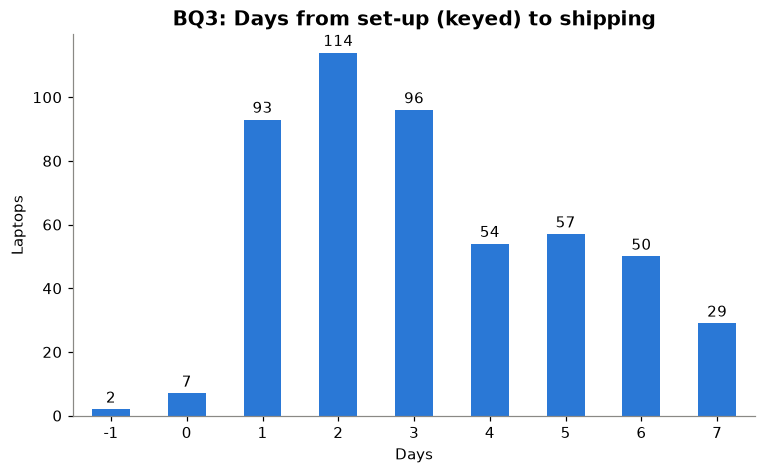

In [16]:
df["days_to_ship"] = (df["shipped"] - df["keyed"]).dt.days
print(df["days_to_ship"].describe().round(1))
print("Shipped before it was keyed (negative days):", (df["days_to_ship"] < 0).sum())
print("Shipped within 3 days:", f"{(df['days_to_ship'].between(0, 3)).sum() / df['days_to_ship'].notna().sum():.1%}")

days_count = df["days_to_ship"].dropna().astype(int).value_counts().sort_index()   # whole days
ax = days_count.plot(kind="bar", color=BLUE, title="BQ3: Days from set-up (keyed) to shipping")
ax.bar_label(ax.containers[0], padding=2); ax.set_xlabel("Days"); ax.set_ylabel("Laptops"); plt.xticks(rotation=0)
plt.savefig("../images/02_bq3_turnaround.png", bbox_inches="tight"); plt.show()

**Finding:** From set-up to shipping takes a **median of 3 days** and never more than 7. **61.8% ship within 3 days.** 2 laptops show a shipping date one day *before* their set-up date, which is a data-entry error.

**Recommendation:** The build step is not the bottleneck; keep it as it is. Add a simple check that the shipping date can't come before the set-up date.

### BQ4 – Shipping waves

shipped
15 Jun     7
22 Jun    52
29 Jun    17
06 Jul    47
13 Jul    63
20 Jul    52
27 Jul     4
03 Aug    55
10 Aug    43
17 Aug    24
24 Aug    75
31 Aug    22
07 Sep    27
14 Sep    14
21 Sep     0
28 Sep     0
05 Oct     0
12 Oct     0
19 Oct     1
dtype: int64
Busiest week: 24 Aug with 75 laptops


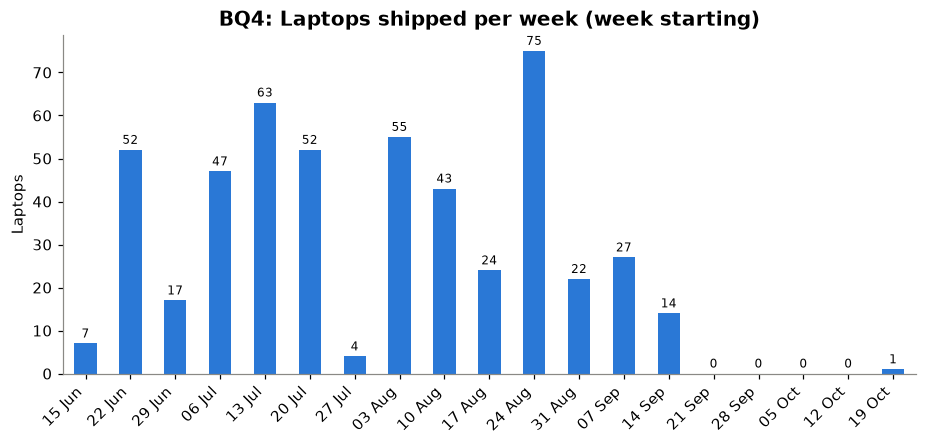

In [17]:
weekly = df.set_index("shipped").resample("W-MON", label="left", closed="left").size()
weekly.index = weekly.index.strftime("%d %b")
print(weekly)
print("Busiest week:", weekly.idxmax(), "with", weekly.max(), "laptops")

ax = weekly.plot(kind="bar", color=BLUE, figsize=(10, 4), title="BQ4: Laptops shipped per week (week starting)")
ax.bar_label(ax.containers[0], padding=2, fontsize=8); ax.set_xlabel(""); ax.set_ylabel("Laptops"); plt.xticks(rotation=45, ha="right")
plt.savefig("../images/03_bq4_weekly_shipping.png", bbox_inches="tight"); plt.show()

**Finding:** Shipping ran in waves, from 7 laptops in the week of 15 Jun to a **peak of 75 in the week of 24 Aug**. Other big weeks were 13 Jul (63), 3 Aug (55) and 22 Jun (52). The programme effectively ended mid-September, with one straggler on 20 Oct.

**Recommendation:** Plan future refreshes around a steady 50–75 laptops a week, the rate this team proved it can sustain, and staff the old-laptop returns for the same pace.

### BQ5 – Old-laptop recovery

In [18]:
shipped_users = df[shipped]
returned = shipped_users["old_laptop_closed"]
label = shipped_users["return_label"]
print(f"Users with a new laptop: {len(shipped_users)}")
print(f"Old laptop back and closed: {returned.sum()} ({returned.mean():.1%})")
print(f"Return label created: {label.sum()} ({label.mean():.1%})")
print(pd.crosstab(label.rename("return label"), returned.rename("old laptop closed"), margins=True))

outstanding = (~returned).sum()
print("Old laptops still out:", outstanding)

Users with a new laptop: 503
Old laptop back and closed: 200 (39.8%)
Return label created: 256 (50.9%)
old laptop closed  False  True  All
return label                       
False                191    56  247
True                 112   144  256
All                  303   200  503
Old laptops still out: 303


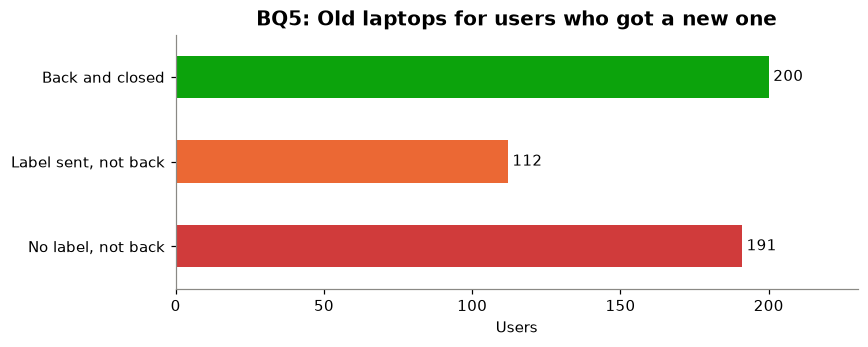

In [19]:
status = pd.Series({
    "Back and closed": int(returned.sum()),
    "Label sent, not back": int((label & ~returned).sum()),
    "No label, not back": int((~label & ~returned).sum()),
})
ax = status.plot(kind="barh", color=[GREEN, ORANGE, RED], figsize=(8, 3), title="BQ5: Old laptops for users who got a new one")
ax.bar_label(ax.containers[0], padding=3); ax.invert_yaxis(); ax.set_xlabel("Users"); ax.set_xlim(0, status.max() * 1.15)
plt.savefig("../images/04_bq5_old_laptop_recovery.png", bbox_inches="tight"); plt.show()

**Finding:** Of the 503 users with a new laptop, **only 200 old laptops (39.8%) are recorded as back and closed**, so **303 are still out**. 112 of those have a return label but haven't come back; 191 have no label at all. 56 laptops came back without a label, probably handed in at an office.

**Recommendation:** Chase the 303 outstanding laptops, starting with the 191 that have no return label. Old devices still hold company data and still count against licences, so this is a security and cost risk, not just admin.

### BQ6 – Home-based (WFH) vs office users

In [20]:
by_type = shipped_users.groupby(shipped_users["wfh"].map({True: "WFH", False: "Office"})).agg(
    users=("old_laptop_closed", "size"),
    old_laptop_back=("old_laptop_closed", "mean"),
    return_label=("return_label", "mean"),
    days_to_ship=("days_to_ship", "median"),
)
by_type[["old_laptop_back", "return_label"]] = (by_type[["old_laptop_back", "return_label"]] * 100).round(1)
print(by_type)

by_prov = shipped_users.groupby("province").agg(users=("old_laptop_closed", "size"), recovered=("old_laptop_closed", "mean"))
by_prov["recovered"] = (by_prov["recovered"] * 100).round(1)
by_prov = by_prov.sort_values("users", ascending=False)
print(by_prov)

        users  old_laptop_back  return_label  days_to_ship
wfh                                                       
Office    423             37.8          43.0           3.0
WFH        80             50.0          92.5           3.0
          users  recovered
province                  
ON          287       42.9
AB           60       13.3
BC           60        1.7
QC           55       98.2
MB           13        0.0
SK           13        0.0
NS            6      100.0
NB            5      100.0
NL            3       66.7
PE            1      100.0


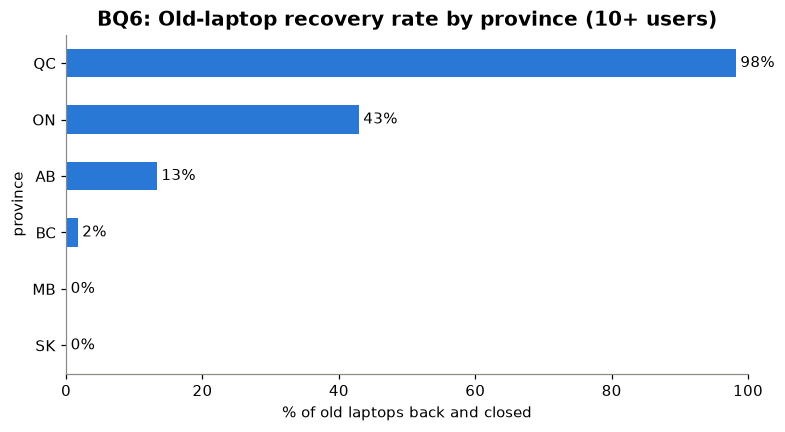

In [21]:
plot = by_prov[by_prov["users"] >= 10]["recovered"].sort_values()
ax = plot.plot(kind="barh", color=BLUE, figsize=(8, 4), title="BQ6: Old-laptop recovery rate by province (10+ users)")
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3); ax.set_xlabel("% of old laptops back and closed"); ax.set_xlim(0, 100)
plt.savefig("../images/05_bq6_recovery_by_province.png", bbox_inches="tight"); plt.show()

**Finding:** **Home-based (WFH) users return old laptops more often (50.0% vs 37.8%)**, and 92.5% of them got a return label against 43.0% of office users. The provinces differ far more: **Quebec records 98.2% returned, Ontario 42.9%, Alberta 13.3% and BC just 1.7%**, and Manitoba and Saskatchewan 0%. Gaps this large suggest different teams recording returns differently, not only laptops not coming back.

**Recommendation:** Copy Quebec's return process (labels plus closing the record) to the western provinces. First confirm with the AB, BC, MB and SK teams whether their old laptops are back but simply not recorded.

## 5. Summary
| # | Question | Answer |
|---|---|---|
| BQ1 | Progress | **503 of 518 (97.1%)** shipped a new laptop |
| BQ2 | Process completion | Set-up steps **95%+**; old laptop back only **38.6%** |
| BQ3 | Turnaround | **Median 3 days** from set-up to shipping, max 7 |
| BQ4 | Shipping waves | Peak **75 laptops** in the week of 24 Aug |
| BQ5 | Old-laptop recovery | **303 old laptops still out** (60.2%) |
| BQ6 | Location | Quebec 98% recovered vs BC 2%; WFH 50% vs office 38% |

**Main message:** the team delivered new laptops quickly and reliably, but the programme stopped at delivery. Recovering and recording the 303 old laptops is the work that remains.